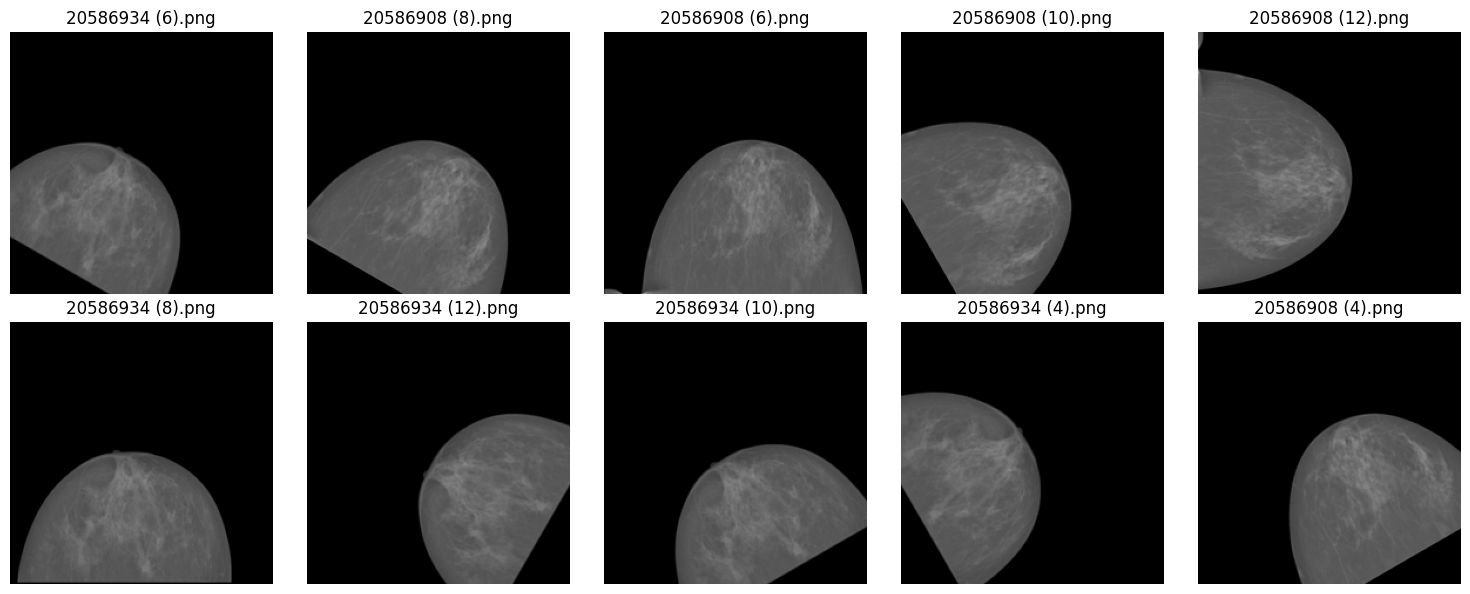

In [1]:
import os
import random
import matplotlib.pyplot as plt
import cv2

# Path to your image folder
img_dir = r"C:/programming/pythonML/computerVision/Breast_cancer/raw_dataset"

# Get all image files from the folder
all_images = [f for f in os.listdir(img_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tiff'))]

# Randomly pick 10 images
random_images = random.sample(all_images, 10)

# Plot images in 2x5 grid
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for i, img_name in enumerate(random_images):
    img_path = os.path.join(img_dir, img_name)
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # Convert BGR to RGB for matplotlib
    
    ax = axes[i // 5, i % 5]
    ax.imshow(img)
    ax.set_title(img_name, fontsize=12)
    ax.axis("off")

plt.tight_layout()
out_dir = r"C:/programming/pythonML/computerVision/Breast_cancer/processed/graphs"

# Ensure the directory exists
os.makedirs(out_dir, exist_ok=True)

# Common save parameters
save_params = dict(dpi=300, transparent=True, bbox_inches='tight')

# Save in multiple formats
for ext in ["png", "pdf", "svg"]:
    plt.savefig(os.path.join(out_dir, f"Sample images from CHSJ Dataset.{ext}"), **save_params)
plt.show()


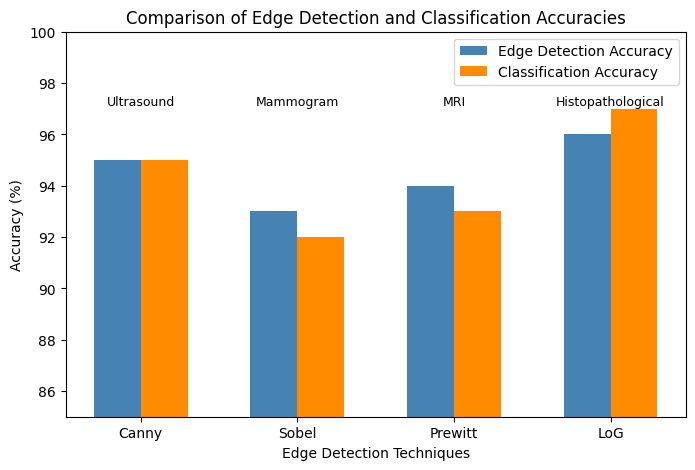

In [10]:
import matplotlib.pyplot as plt
import numpy as np
import os

# Data
techniques = ["Canny", "Sobel", "Prewitt", "LoG"]
edge_detection_accuracy = [95, 93, 94, 96]
classification_accuracy = [95, 92, 93, 97]

x = np.arange(len(techniques))  # X-axis positions
width = 0.3  # Width of bars

# Plot
fig, ax = plt.subplots(figsize=(8, 5))

bars1 = ax.bar(x - width/2, edge_detection_accuracy, width, label='Edge Detection Accuracy', color='steelblue')
bars2 = ax.bar(x + width/2, classification_accuracy, width, label='Classification Accuracy', color='darkorange')

# Labels & Title
ax.set_ylabel("Accuracy (%)")
ax.set_xlabel("Edge Detection Techniques")
ax.set_title("Comparison of Edge Detection and Classification Accuracies")
ax.set_xticks(x)
ax.set_xticklabels(techniques)
ax.set_ylim(85, 100)  # Y-axis range

# Adding custom annotations (like Ultrasound, Mammogram, etc.)
annotations = ["Ultrasound", "Mammogram", "MRI", "Histopathological"]
for i, label in enumerate(annotations):
    ax.text(x[i], 97, label, ha='center', va='bottom', fontsize=9, color="black", alpha=1)

# Legend
ax.legend()

out_dir = r"C:/programming/pythonML/computerVision/Breast_cancer/processed/graphs"

# Ensure the directory exists
os.makedirs(out_dir, exist_ok=True)

# Common save parameters
save_params = dict(dpi=300, transparent=True, bbox_inches='tight')

# Save in multiple formats
for ext in ["png", "pdf", "svg"]:
    plt.savefig(os.path.join(out_dir, f"edge_detection_classification_accuracy.{ext}"), **save_params)

plt.show()


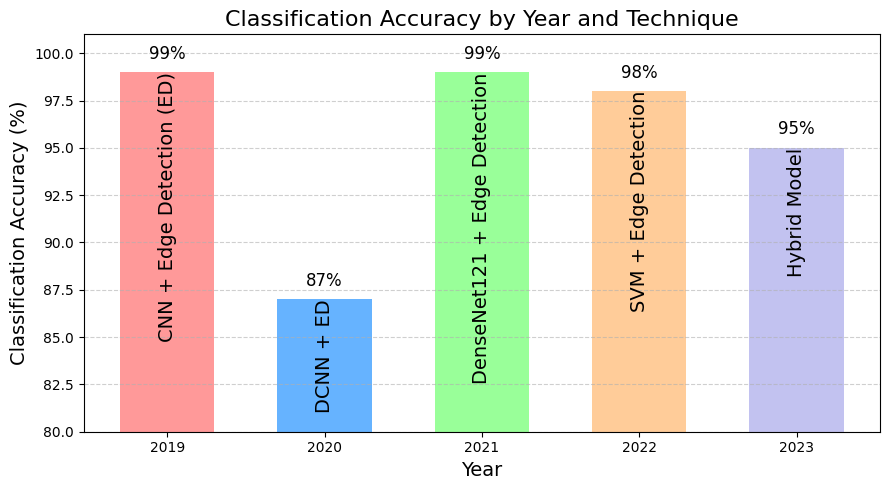

In [11]:
#### Literature review bar graph with label bold #############


import matplotlib.pyplot as plt

# Data
years = [2019, 2020, 2021, 2022, 2023]
accuracy = [99, 87, 99, 98, 95]
techniques = [
    "CNN + Edge Detection (ED)",
    "DCNN + ED",
    "DenseNet121 + Edge Detection",
    "SVM + Edge Detection",
    "Hybrid Model"
]
colors = ['#ff9999', '#66b3ff', '#99ff99', '#ffcc99', '#c2c2f0']

# Plot
plt.figure(figsize=(9,5))
bars = plt.bar(years, accuracy, color=colors, width=0.6)

# Add accuracy values ABOVE bars
for bar, acc in zip(bars, accuracy):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f'{acc}%', ha='center', va='bottom', fontsize=12)

# Add technique labels INSIDE bars (center vertically)
for bar, tech in zip(bars, techniques):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height,   # middle of bar
             tech, ha='center', va='top', rotation=90,
             fontsize=14, color='black')

# Titles and labels
plt.title("Classification Accuracy by Year and Technique", fontsize=16)
plt.xlabel("Year", fontsize=14)
plt.ylabel("Classification Accuracy (%)", fontsize=14)

# Y-axis limits
plt.ylim(80, 101)

# Show grid
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
# Save the figure all in grpahs folder
out_dir = r"C:/programming/pythonML/computerVision/Breast_cancer/processed/graphs"

# Ensure the directory exists
os.makedirs(out_dir, exist_ok=True)

# Common save parameters
save_params = dict(dpi=300, transparent=True, bbox_inches='tight')

# Save in multiple formats
for ext in ["png", "pdf", "svg"]:
    plt.savefig(os.path.join(out_dir, f"classfication accuracy by years.{ext}"), **save_params)
plt.show()


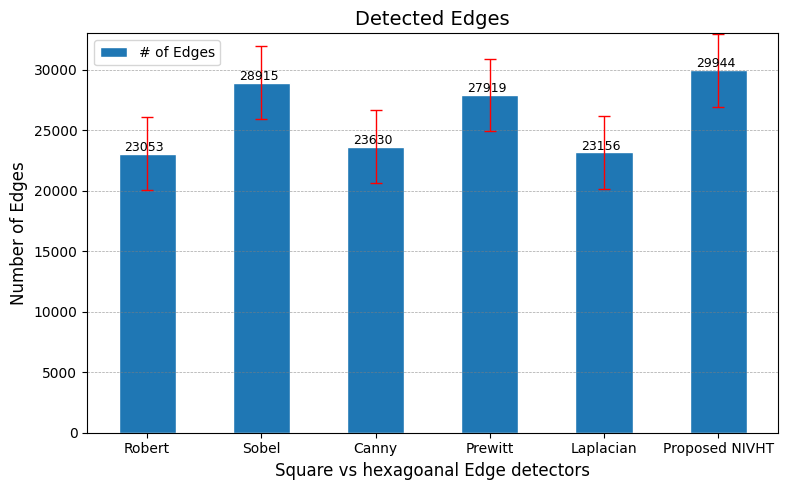

In [12]:
import matplotlib.pyplot as plt
import numpy as np

# Data
methods = ["Robert", "Sobel", "Canny", "Prewitt", "Laplacian", "Proposed NIVHT"]
edges = [23053, 28915, 23630, 27919, 23156, 29944]

# Example error values (adjust if you have exact ones)
errors = [3000, 3000, 3000, 3000, 3000, 3000]

x = np.arange(len(methods))

# Plot
fig, ax = plt.subplots(figsize=(8, 5))

bar_width = 0.5  

bars = ax.bar(x, edges,width=bar_width, color="tab:blue", edgecolor="white", label="# of Edges", yerr=errors, capsize=4, error_kw={'elinewidth':1, 'ecolor':'red'})

# ✅ Add horizontal grid lines across the axes
ax.yaxis.grid(True, linestyle='--', linewidth=0.5, color='gray', alpha=0.7)

# Add values inside bars
for bar, value in zip(bars, edges):
    ax.text(bar.get_x()+0.1 + bar.get_width()/4, bar.get_height()-10, f'{value}', 
            ha='center', va='bottom', fontsize=9, color='black')

# Title and labels
ax.set_title("Detected Edges", fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(methods, fontsize=10)
ax.set_ylabel("Number of Edges", fontsize=12)  
ax.set_xlabel("Square vs hexagoanal Edge detectors", fontsize=12)

# Y-axis limit
ax.set_ylim(0, 33000)
# Legend
ax.legend()
plt.tight_layout()

# Save the figure all in grpahs folder
out_dir = r"C:/programming/pythonML/computerVision/Breast_cancer/processed/graphs"

# Ensure the directory exists
os.makedirs(out_dir, exist_ok=True)

# Common save parameters
save_params = dict(dpi=300, transparent=True, bbox_inches='tight')

# Save in multiple formats
for ext in ["png", "pdf", "svg"]:
    plt.savefig(os.path.join(out_dir, f"Number of edge detected.{ext}"), **save_params)
plt.show()


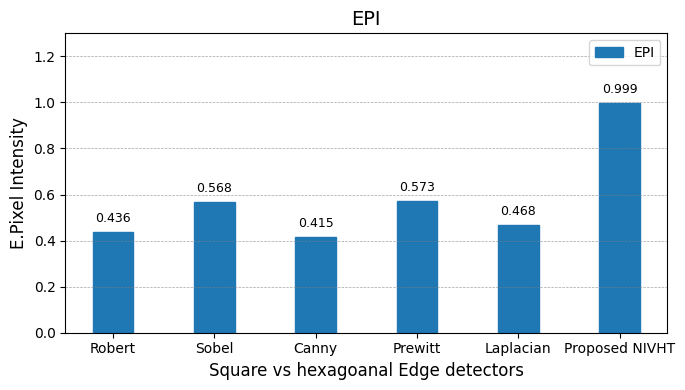

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import os

# Data
methods = ["Robert", "Sobel", "Canny", "Prewitt", "Laplacian", "Proposed NIVHT"]
epi_values = [0.436, 0.568, 0.415, 0.573, 0.468, 0.999]

x = np.arange(len(methods))

# Plot
fig, ax = plt.subplots(figsize=(7, 4))

# ✅ Control bar width here (default is 0.8)
bar_width = 0.4  

bars = ax.bar(x, epi_values, width=bar_width, color="tab:blue", edgecolor="tab:blue", label="EPI")

# Add black values on top of bars with padding
for bar, value in zip(bars, epi_values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.03, f'{value:.3f}', 
            ha='center', va='bottom', fontsize=9, color='black')

# ✅ Add horizontal grid lines across the axes
ax.yaxis.grid(True, linestyle='--', linewidth=0.5, color='gray', alpha=0.7)

# Title
ax.set_title("EPI", fontsize=14)

# Axis labels
ax.set_xticks(x)
ax.set_xticklabels(methods, fontsize=10)
ax.set_ylabel("E.Pixel Intensity", fontsize=12)  
ax.set_xlabel("Square vs hexagoanal Edge detectors", fontsize=12)  

# Y-axis range
ax.set_ylim(0, 1.3)

# Legend
ax.legend()

plt.tight_layout()

# Save the figure all in graphs folder
out_dir = r"C:/programming/pythonML/computerVision/Breast_cancer/processed/graphs"
os.makedirs(out_dir, exist_ok=True)

save_params = dict(dpi=300, transparent=True, bbox_inches='tight')
for ext in ["png", "pdf", "svg"]:
    plt.savefig(os.path.join(out_dir, f"EPI_graph.{ext}"), **save_params)

plt.show()


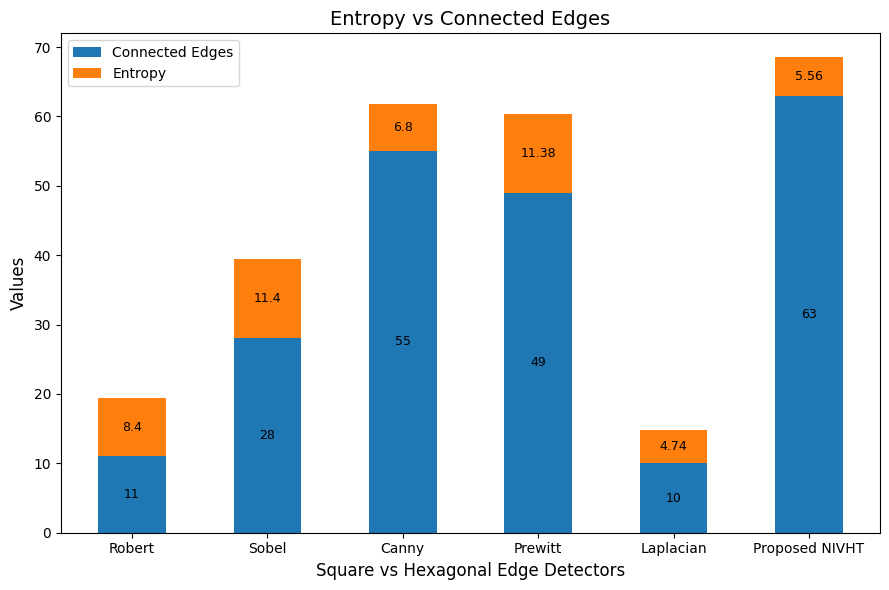

In [14]:
import matplotlib.pyplot as plt
import numpy as np

# Data from the chart
methods = ["Robert", "Sobel", "Canny", "Prewitt", "Laplacian", "Proposed NIVHT"]
connected_edges = [11, 28, 55, 49, 10, 63]
entropy = [8.4, 11.4, 6.8, 11.38, 4.74, 5.56]

# X positions
x = np.arange(len(methods))
width = 0.5  # Width of bars

# Create figure and axis
fig, ax = plt.subplots(figsize=(9, 6))

# Plot stacked bar
bars1 = ax.bar(x, connected_edges, width=width, label="Connected Edges", color="tab:blue")
bars2 = ax.bar(x, entropy, width=width, bottom=connected_edges, label="Entropy", color="tab:orange")

# Add text labels on bars
for i in range(len(methods)):
    ax.text(x[i], connected_edges[i] / 2, str(connected_edges[i]), 
            ha='center', va='center', color='black', fontsize=9)
    ax.text(x[i], connected_edges[i] + entropy[i] / 2, str(entropy[i]), 
            ha='center', va='center', color='black', fontsize=9)

# Axis labels and ticks
ax.set_xticks(x)
ax.set_xticklabels(methods, fontsize=10)
ax.set_ylabel("Values", fontsize=12)
ax.set_xlabel("Square vs Hexagonal Edge Detectors", fontsize=12)

# Title and legend
ax.set_title("Entropy vs Connected Edges", fontsize=14)
ax.legend()

plt.tight_layout()

# Save the figure all in graphs folder
out_dir = r"C:/programming/pythonML/computerVision/Breast_cancer/processed/graphs"
os.makedirs(out_dir, exist_ok=True)

save_params = dict(dpi=300, transparent=True, bbox_inches='tight')
for ext in ["png", "pdf", "svg"]:
    plt.savefig(os.path.join(out_dir, f"Entropy Vs Connected Edges.{ext}"), **save_params)
plt.show()


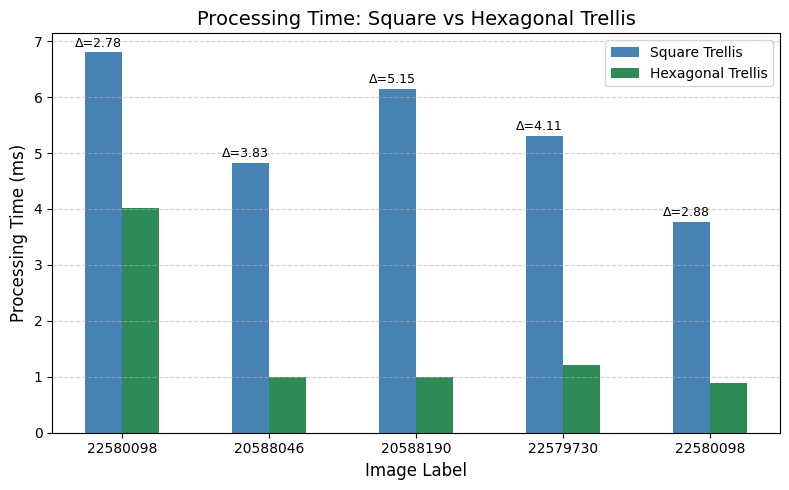

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# --- Data ---
data = {
    "Image Label": [22580098, 20588046, 20588190, 22579730, 22580098],
    "Conventional Square Interpolation": [6.80, 4.83, 6.15, 5.31, 3.77],
    "Proposed NIVHT (Hexagonal Trellis)": [4.016, 0.999, 1.001, 1.202, 0.890],
}
df = pd.DataFrame(data)
df["Difference"] = df["Conventional Square Interpolation"] - df["Proposed NIVHT (Hexagonal Trellis)"]

# --- Plotting ---
x = np.arange(len(df))  # image positions
width = 0.25  # bar width

plt.figure(figsize=(8, 5))

# Grouped bars
plt.bar(x - width/2, df["Conventional Square Interpolation"], width, label="Square Trellis", color="steelblue")
plt.bar(x + width/2, df["Proposed NIVHT (Hexagonal Trellis)"], width, label="Hexagonal Trellis", color="seagreen")

# Annotate difference on top
for i in range(len(df)):
    diff = df["Difference"].iloc[i]
    plt.text(x[i], max(df["Conventional Square Interpolation"].iloc[i], df["Proposed NIVHT (Hexagonal Trellis)"].iloc[i]) + 0.1,
             f"Δ={diff:.2f}", ha="right", fontsize=9, color="black")

# Labels and styling
plt.xticks(x, df["Image Label"].astype(str), rotation=0)
plt.ylabel("Processing Time (ms)", fontsize=12)
plt.xlabel("Image Label", fontsize=12)
plt.title("Processing Time: Square vs Hexagonal Trellis", fontsize=14)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
# Save the figure all in graphs folder
out_dir = r"C:/programming/pythonML/computerVision/Breast_cancer/processed/graphs"
os.makedirs(out_dir, exist_ok=True)

save_params = dict(dpi=300, transparent=True, bbox_inches='tight')
for ext in ["png", "pdf", "svg"]:
    plt.savefig(os.path.join(out_dir, f"Processing time and difference.{ext}"), **save_params)

plt.show()
